# Demo: từ video thô đến bản đồ 2D

In [1]:
import os, time, warnings
import cv2
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import demo
from src.pitch_localization import load_homography
from src.visualize_2d import PitchCanvas, boxes_at, draw_tracks, side_by_side, tracks_to_pitch

VIDEO   = os.path.join(demo.DATA, "wide_view", "videos", "F_20200220_1_0720_0750.mp4")
OUT_DIR = os.path.join(demo.BASE, "Output", "demo_notebook")
FRAME   = 300                                   # frame dùng để minh họa từng bước
os.makedirs(OUT_DIR, exist_ok=True)

def show(img, title="", h=3.2):
    plt.figure(figsize=(16, h)); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title); plt.axis("off"); plt.show()

def read_frame(path, idx):
    cap = cv2.VideoCapture(path); cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, f = cap.read(); cap.release(); return f

## 0. Video đầu vào

F_20200220_1_0720_0750.mp4: 6500x1000, 750 frames @ 25 fps


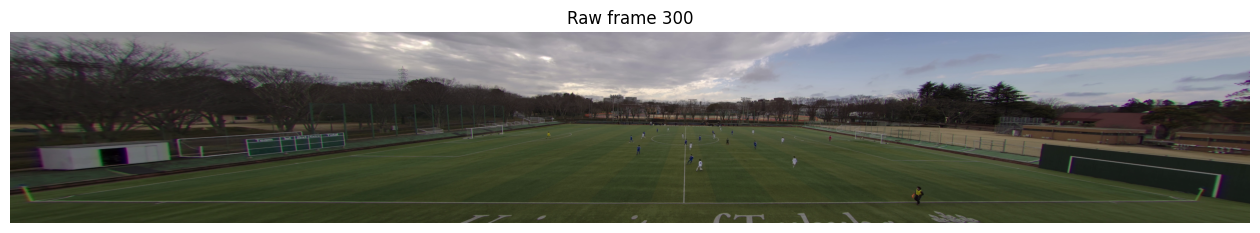

In [2]:
cap = cv2.VideoCapture(VIDEO)
fps, n = cap.get(cv2.CAP_PROP_FPS), int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
W, H_img = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)); cap.release()
print(f"{os.path.basename(VIDEO)}: {W}x{H_img}, {n} frames @ {fps:.0f} fps")
frame = read_frame(VIDEO, FRAME)
show(frame, f"Raw frame {FRAME}")

## 1. Detection (YOLO26)

[Detector] YOLO loaded on cuda


Missing: 0 | Unexpected: 8
[FeatureExtractor] SOLIDER (swin_small) loaded on cuda
[FeatureExtractor] Feature dim: 768


20 detections ở frame 300


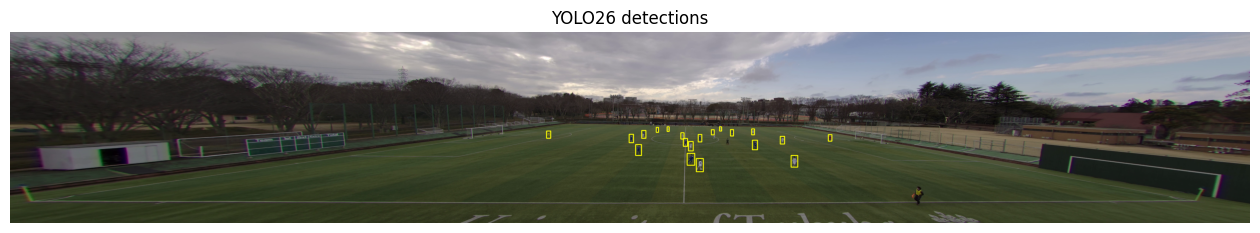

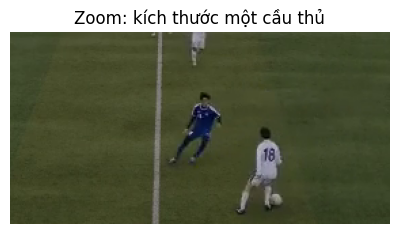

In [3]:
detector, extractor_refine = demo.build_components("optimal")
dets = detector.detect(frame)
vis = frame.copy()
for x1, y1, x2, y2, conf in dets:
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 255), 4)
print(f"{len(dets)} detections ở frame {FRAME}")
show(vis, "YOLO26 detections")
x1, y1, x2, y2, _ = max(dets, key=lambda d: d[2] - d[0])
show(frame[max(0, y1 - 40):y2 + 40, max(0, x1 - 120):x2 + 120], "Zoom: kích thước một cầu thủ", h=2.5)

## 2. Tracking online (ByteTrack)


[MOT] Done — 750 frames, 53 tracks
[MOT] Normal time:43.71 seconds, extract (refiner) time: 195.20 seconds
Online: 53 IDs | detect+track 43.7s | SOLIDER embedding 195.2s


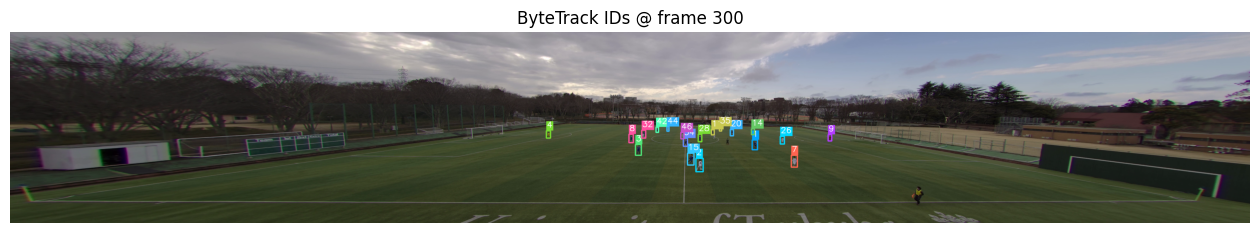

In [4]:
t0 = time.time()
online, t_track, t_extract = demo.track_online(VIDEO, detector, extractor_refine)
print(f"Online: {len(online)} IDs | detect+track {t_track:.1f}s | SOLIDER embedding {t_extract:.1f}s")
show(draw_tracks(read_frame(VIDEO, FRAME), boxes_at(online, FRAME), thickness=5, font_scale=1.4),
     f"ByteTrack IDs @ frame {FRAME}")

## 3. GTA

[GTALink] Trước split: 53 tracklets


[GTALink] Sau  split: 61 tracklets


[GTALink] Trước merge: 61 tracklets


[GTALink] Sau  merge: 23 tracklets
GTALink: 53 → 23 IDs trong 8.0s


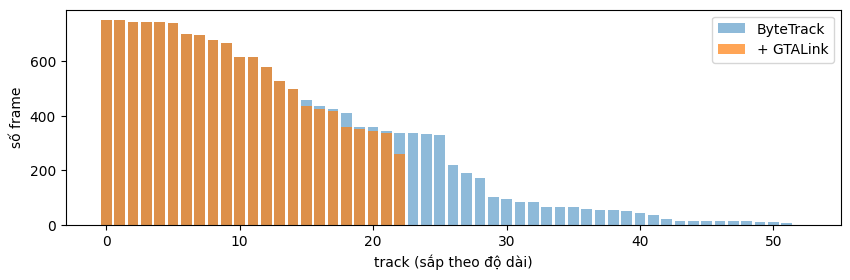

In [5]:
t0 = time.time()
refined = demo.refine_offline(online)
print(f"GTALink: {len(online)} → {len(refined)} IDs trong {time.time() - t0:.1f}s")
lens = lambda tr: sorted((len(d["frames"]) for d in tr.values()), reverse=True)
plt.figure(figsize=(10, 2.8))
plt.bar(range(len(lens(online))), lens(online), alpha=.5, label="ByteTrack")
plt.bar(range(len(lens(refined))), lens(refined), alpha=.7, label="+ GTALink")
plt.xlabel("track (sắp theo độ dài)"); plt.ylabel("số frame"); plt.legend(); plt.show()

## 4. Chiếu lên sân (homography)

[pitch_localization] H computed — inliers: 62/65


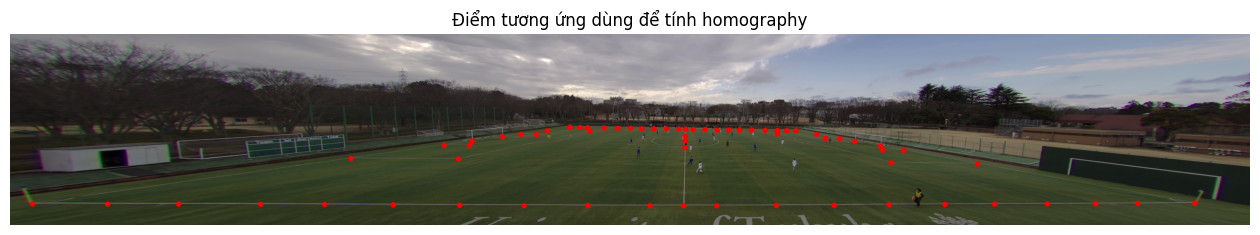

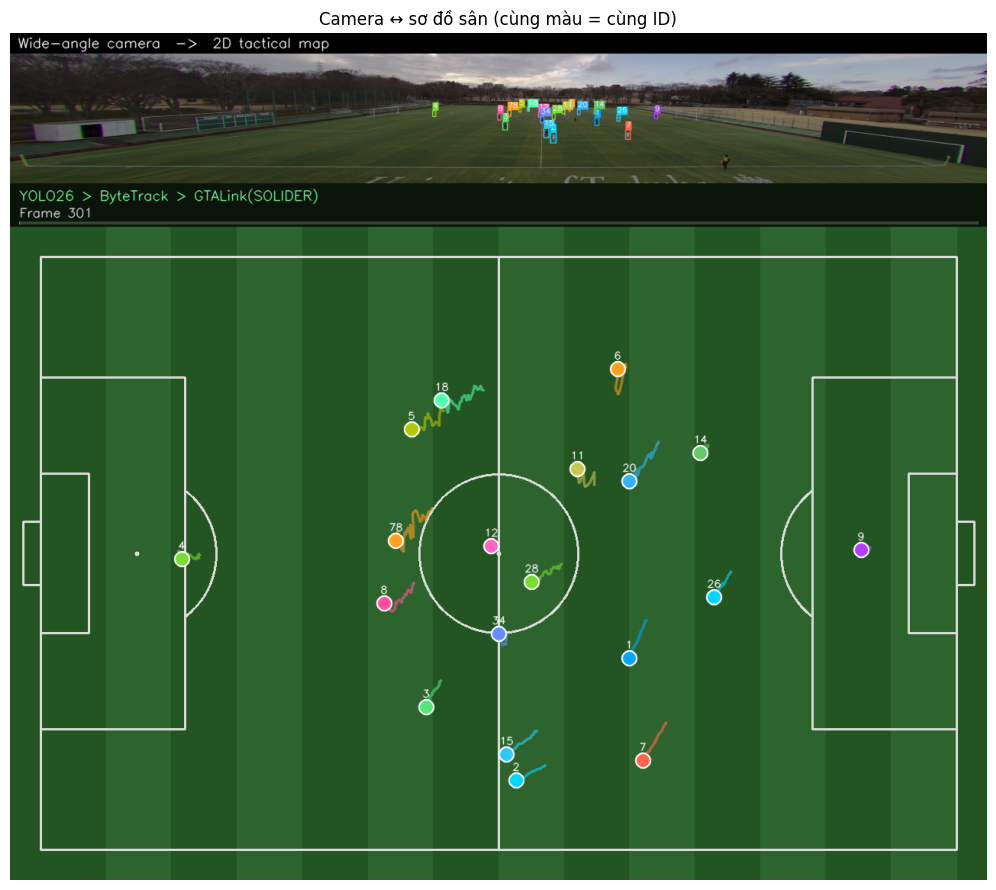

In [6]:
import json
H, _ = load_homography(demo.KEYPOINTS)
kp = json.load(open(demo.KEYPOINTS))
vis = frame.copy()
for k, (px, py) in kp.items():
    cv2.circle(vis, (int(px), int(py)), 14, (0, 0, 255), -1)
show(vis, "Điểm tương ứng dùng để tính homography")

tracks = demo.strip_feats(refined)
pos = tracks_to_pitch(tracks, H)
canvas = PitchCanvas(width=1280)
for f in range(FRAME - 30, FRAME + 1):          # chạy 30 frame trước để có vệt di chuyển
    pitch = canvas.render(pos.get(f, {}), title=demo.PIPELINE_NAME["optimal"], info=f"Frame {f + 1}")
cam = draw_tracks(read_frame(VIDEO, FRAME), boxes_at(tracks, FRAME), thickness=6, font_scale=1.6)
cam = cv2.resize(cam, (W // 2, H_img // 2))
show(side_by_side(cam, pitch, "Wide-angle camera  ->  2D tactical map"), "Camera ↔ sơ đồ sân (cùng màu = cùng ID)", h=11)

## 5. Xuất video

In [7]:
paths = demo.render(VIDEO, tracks, H, OUT_DIR, demo.PIPELINE_NAME["optimal"],
                    gif_path=os.path.join(OUT_DIR, "demo.gif"))
for k, p in paths.items():
    print(f"{k:>15}: {os.path.relpath(p, demo.BASE)}")

 tracked_camera: Output\demo_notebook\tracked_camera.mp4
       pitch_2d: Output\demo_notebook\pitch_2d.mp4
   side_by_side: Output\demo_notebook\side_by_side.mp4
   trajectories: Output\demo_notebook\trajectories.csv
            gif: Output\demo_notebook\demo.gif


## 6. Đánh giá

In [8]:
import pandas as pd
m = demo.evaluate(VIDEO, tracks, H)
print(pd.Series(m).round(3).to_string())

ref = os.path.join(demo.BASE, "Output", "pitch_eval", "pitch_eval_per_video.csv")
if os.path.exists(ref):                          # số liệu của cùng video trong bảng kết quả
    df = pd.read_csv(ref)
    print(df[df.video == os.path.basename(VIDEO)].set_index("Pipeline")[["Pitch-HOTA", "E_1to1"]].round(3))

MOTA          71.130
IDF1          72.440
HOTA          30.770
IDs            7.000
Pitch-HOTA    42.872
E_1to1         4.894
                          Pitch-HOTA  E_1to1
Pipeline                                    
Oracle (GT boxes)             61.444   3.777
Baseline                      13.645   5.219
Baseline (trained)            30.730   6.147
YOLO26 + ByteTrack            42.542   5.032
YOLO26 + ByteTrack + GTA      42.872   4.894
